# 4. Linking USTC and BNE editions

Many editions are in both catalogs. Here I measure how much the two overlap, since the counts in this repository add catalog
records and an edition held in both catalogs counts twice.

Method: within the same year, I compare the beginning of the titles with character n-grams (cosine similarity). Each BNE record
keeps its most similar USTC edition; I count as linked the pairs above `MIN_SCORE`.

---

# 4. Enlace de ediciones del USTC y la BNE

Muchas ediciones están en los dos catálogos. Acá mido cuánto se superponen, porque los conteos de este repositorio suman registros
de catálogo y una edición presente en ambos cuenta dos veces.

Método: dentro del mismo año, comparo el comienzo de los títulos con n-gramas de caracteres (similitud de coseno). Cada registro
de la BNE se queda con la edición del USTC más parecida; cuento como enlazados los pares que superan `MIN_SCORE`.

In [1]:
# Celda 1
# Paths and parameters:
%cd "E:/No sincroniza/Software desarrollado/spanish-imprints-counts"
DATA = "E:/Datos/spanish_imprints"
USTC = DATA + "/ustc_spanish.jsonl"
CATALOG = DATA + "/bne/monoantiguas-UTF8.zip"
OUT = DATA + "/link_ustc_bne.tsv"
YEAR_FROM, YEAR_TO = 1501, 1700
TITLE_CHARS = 100     # Only the beginning of the title: USTC titles are short, BNE titles are full transcriptions.
MIN_SCORE = 0.6

E:\No sincroniza\Software desarrollado\spanish-imprints-counts


In [2]:
# Celda 2
import zipfile
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from helpers import norm

## 1. Which titles do I compare? / ¿Qué títulos comparo?

In [3]:
# Celda 3
ustc = pd.read_json(USTC, lines=True, dtype={"id": str}).drop_duplicates("id")
ustc["year"] = pd.to_numeric(ustc["year"], errors="coerce")
ustc = ustc[(ustc["year"] >= YEAR_FROM) & (ustc["year"] <= YEAR_TO)][["id", "year", "title", "authorship"]]

bne = pd.read_csv(zipfile.ZipFile(CATALOG).open("moa/monoantiguas-UTF8.csv"), sep=";", dtype=str,
                  usecols=["id", "fecha_de_publicacion", "lengua_principal", "titulo", "autores"])
bne["year"] = pd.to_numeric(bne["fecha_de_publicacion"], errors="coerce")
bne = bne[(bne["year"] >= YEAR_FROM) & (bne["year"] <= YEAR_TO) & (bne["lengua_principal"] == "español")]
bne["id"] = bne["id"].str.strip()
print("USTC:", len(ustc), "| BNE:", len(bne))

USTC: 81937 | BNE: 42588


In [4]:
# Celda 4
# "Exercicios espirituales, compuestos por..." -> first 100 normalized characters:
ustc["key"] = ustc["title"].map(norm).str.split().str.join(" ").str[:TITLE_CHARS]
bne["key"] = bne["titulo"].map(norm).str.split().str.join(" ").str[:TITLE_CHARS]
vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 4), min_df=2, max_features=100_000, dtype="float32")
vectorizer.fit(pd.concat([ustc["key"], bne["key"]]))

c:\users\fabi_\appdata\local\programs\python\python39\lib\site-packages\sklearn\feature_extraction\text.py:2043: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(


TfidfVectorizer(analyzer='char_wb', dtype='float32', max_features=100000,
                min_df=2, ngram_range=(3, 4))

## 2. Which USTC edition is closest to each BNE record? / ¿Qué edición del USTC se parece más a cada registro de la BNE?

In [5]:
# Celda 5
rows = []
for year, b in bne.groupby("year"):
    u = ustc[ustc["year"] == year]
    if len(u) == 0:
        continue
    sim = vectorizer.transform(b["key"]) @ vectorizer.transform(u["key"]).T   # BNE x USTC similarities.
    best = sim.argmax(axis=1).A1
    score = sim.max(axis=1).toarray().ravel()
    rows.append(pd.DataFrame({"bne_id": b["id"].values, "ustc_id": u["id"].values[best], "score": score, "year": year}))
pairs = pd.concat(rows)
pairs["score"].describe()

count    42588.000000
mean         0.632651
std          0.332005
min          0.018721
25%          0.287013
50%          0.692971
75%          1.000000
max          1.000001
Name: score, dtype: float64

<Axes: ylabel='Frequency'>

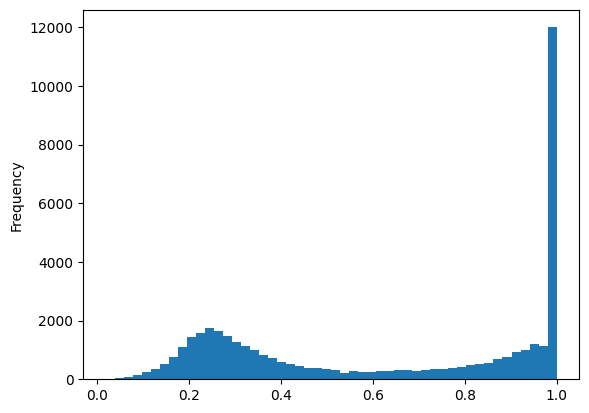

In [6]:
# Celda 6
# Distribution of the best score: a second peak at high values = true matches:
pairs["score"].plot(kind="hist", bins=50)

In [7]:
# Celda 7
# Pairs around the threshold, to check it by eye:
check = pairs[(pairs["score"] > MIN_SCORE - 0.05) & (pairs["score"] < MIN_SCORE + 0.05)].sample(10, random_state=1)
check = check.merge(bne[["id", "titulo"]], left_on="bne_id", right_on="id").merge(ustc[["id", "title"]], left_on="ustc_id", right_on="id")
for _, r in check.iterrows():
    print(f"{r['score']:.2f} | BNE: {r['titulo'][:90]}\n     | USTC: {r['title'][:90]}\n")

0.62 | BNE: Coronica de las Indias ::  la hystoria general de las Indias agora nueuamente impressa cor
     | USTC: Coronica de las Indias

0.64 | BNE: Por D. Enrique Enriquez de Guzman, Conde de Alua. Con D. Antonio Pimentel, Marques de Taua
     | USTC: En el pleyto que es entre don Enrique Enriquez de Guzman, conde de Alva de Aliste, por si 

0.58 | BNE: Parte del Atlas Mayor, o Geographia Blaviana, que contiene las cartas y descripciones de l
     | USTC: Atlas mayor, sino Cosmographia Blaviana

0.65 | BNE: Panigirico en alabanza de la serenissima alteza del Gran Francisco de Este Duque potentiss
     | USTC: Panegirico en alabanza de la alteza de san Francisco del este duque de Modena cuando entro

0.59 | BNE: La Condesa vandolera ::  comedia famosa.
     | USTC: La vanda y la flor. Comedia famosa

0.59 | BNE: Dechado de varios subiectos:
     | USTC: Dechado de varios subjectos

0.58 | BNE: Forma del juramento, y boto que por el misterio de la Inmaculada Concepcion de la Virgen M

## 3. How much do the catalogs overlap? / ¿Cuánto se superponen los catálogos?

In [8]:
# Celda 8
linked = pairs[pairs["score"] >= MIN_SCORE]
linked.to_csv(OUT, sep="\t", index=False)
print("BNE records linked to a USTC edition:", len(linked), f"of {len(bne)} ({100 * len(linked) / len(bne):.1f} %)")
print("USTC editions linked to a BNE record:", linked["ustc_id"].nunique(), f"of {len(ustc)} ({100 * linked['ustc_id'].nunique() / len(ustc):.1f} %)")
print("USTC editions with more than one BNE record:", (linked["ustc_id"].value_counts() > 1).sum())

BNE records linked to a USTC edition: 22661 of 42588 (53.2 %)
USTC editions linked to a BNE record: 20463 of 81937 (25.0 %)
USTC editions with more than one BNE record: 1798


In [9]:
# Celda 9
# Share linked per decade (BNE side):
pairs["decade"] = pairs["year"] // 10 * 10
pairs["linked"] = pairs["score"] >= MIN_SCORE
(100 * pairs.groupby("decade")["linked"].mean()).round(1)

decade
1500.0    40.6
1510.0    46.9
1520.0    52.7
1530.0    51.4
1540.0    68.3
1550.0    62.4
1560.0    58.2
1570.0    54.8
1580.0    56.2
1590.0    52.7
1600.0    24.7
1610.0    43.0
1620.0    45.4
1630.0    45.7
1640.0    52.0
1650.0    57.2
1660.0    68.3
1670.0    70.6
1680.0    71.2
1690.0    72.7
1700.0    40.1
Name: linked, dtype: float64